# Lab 4: Clustering — Solutions

In this lab we implement k-means, agglomerative clustering and the k-NN distance curve of DBSCAN from scratch with NumPy, and use DBSCAN and HDBSCAN from scikit-learn. At home, DBSCAN and HDBSCAN are implemented from scratch.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.cluster import hierarchy
from sklearn.datasets import make_moons, make_blobs
from sklearn.cluster import AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.metrics import adjusted_rand_score
plt.style.use("seaborn-v0_8")

## Helpers

`cdist(A, B)` (from SciPy) returns the table of distances between every row of `A` and every row of `B`, with shape `(len(A), len(B))`. We use it in every exercise.

**`plot_clusters`** draws the points coloured by their cluster. Points labelled −1 are noise (DBSCAN and HDBSCAN) and are drawn in grey. Run the cell and move on.

In [2]:
def plot_clusters(X, labels, title=None, ax=None):
    """Scatter the 2D points X, coloured by their cluster label; label -1 (noise) is drawn in grey.

    ax: optional matplotlib axis, to draw inside a grid of subplots
    """
    # create a new figure if no axis is given
    if ax is None:
        ax = plt.figure(figsize=(6, 5)).gca()

    # noise points in grey, clustered points coloured by their label
    noise = labels == -1
    ax.scatter(X[noise, 0], X[noise, 1], color="0.7", s=10)
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise], cmap="tab10", s=20)

    # title with the number of clusters
    n_clusters = len(np.unique(labels[~noise]))
    ax.set_title(f"{title}: {n_clusters} clusters" if title else f"{n_clusters} clusters")

## Clustering two datasets

We use two datasets without labels:
- **toy data**: two half-moons and two round blobs (100 points);
- **noisy data**: 2309 points with clusters of different shapes and densities, plus background noise.

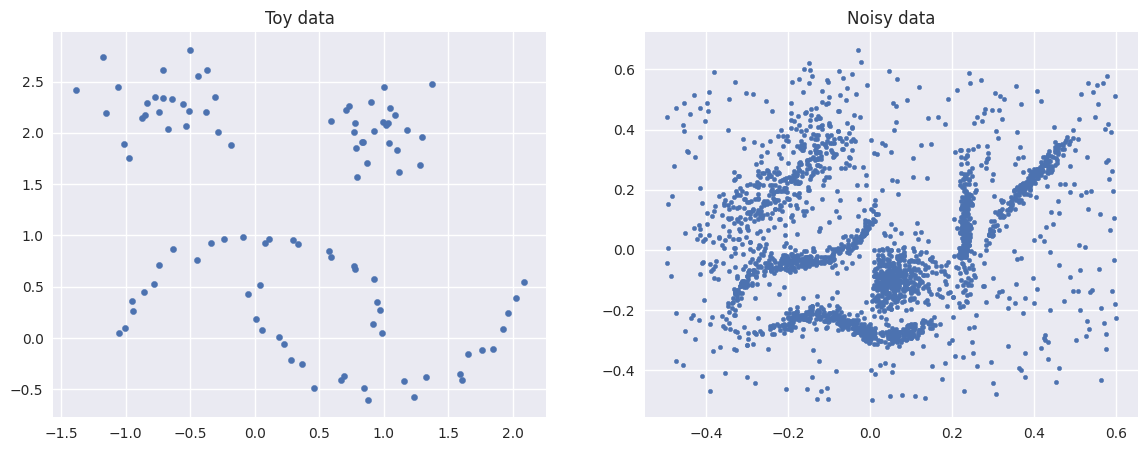

In [3]:
moons, _ = make_moons(n_samples=50, noise=0.05, random_state=0)
blobs, _ = make_blobs(n_samples=50, centers=[(-0.75, 2.25), (1.0, 2.0)], cluster_std=0.25, random_state=0)
X_toy = np.vstack([moons, blobs])
X_noisy = np.load("clusterable_data.npy")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_toy[:, 0], X_toy[:, 1], s=20)
axes[0].set_title("Toy data")
axes[1].scatter(X_noisy[:, 0], X_noisy[:, 1], s=10)
axes[1].set_title("Noisy data")
plt.show()

### 1.1 K-means

K-means looks for $K$ centres $\mu_1, \dots, \mu_K$ and puts each point in the cluster of its nearest centre. It minimises the **inertia**, the sum of the squared distances between each point and its centre:
$$
\text{inertia} = \sum_{i=1}^{n} \| x_i - \mu_{c_i} \|^2 ,
$$
where $c_i$ is the cluster of point $i$. **Lloyd's algorithm** starts from $K$ random points of the data as centres, and repeats two steps until the centres stop moving:
1. **assign**: each point goes to the cluster of its nearest centre;
2. **update**: each centre moves to the mean of the points of its cluster.

**Exercise 1.** Complete `KMeans`.

In [4]:
class KMeans:
    """K-means clustering with Lloyd's algorithm."""

    def __init__(self, n_clusters, n_iter=100, seed=0):
        self.n_clusters = n_clusters  # K
        self.n_iter = n_iter          # maximum number of iterations
        self.seed = seed              # seed of the random starting centres
        self.centers_ = None          # (K, num_features) array of the centres
        self.labels_ = None           # cluster of every training point
        self.inertia_ = None          # sum of the squared distances to the centres

    def predict(self, X):
        """Index of the nearest centre for every row of X."""
        # Step 1: distances between every point and every centre
        distances = cdist(X, self.centers_)  # shape (num_samples, K)

        # Step 2: index of the nearest centre
        return np.argmin(distances, axis=1)

    def fit(self, X):
        """Run Lloyd's algorithm on the data X, of shape (num_samples, num_features)."""
        # Step 1: K different random rows of X as starting centres
        rng = np.random.RandomState(self.seed)
        rows = rng.choice(len(X), self.n_clusters, replace=False)
        self.centers_ = X[rows]

        # Step 2: Lloyd's iterations
        for _ in range(self.n_iter):
            # a) assign each point to its nearest centre
            labels = self.predict(X)

            # b) move each centre to the mean of its points
            new_centers = np.array([X[labels == k].mean(axis=0) for k in range(self.n_clusters)])

            # c) stop when the centres no longer move
            if np.allclose(new_centers, self.centers_):
                break

            # d) keep the new centres
            self.centers_ = new_centers

        # Step 3: final labels
        self.labels_ = self.predict(X)

        # Step 4: inertia
        self.inertia_ = np.sum((X - self.centers_[self.labels_]) ** 2)
        return self

Run k-means with $K = 4$ on the toy data and $K = 6$ on the noisy data:

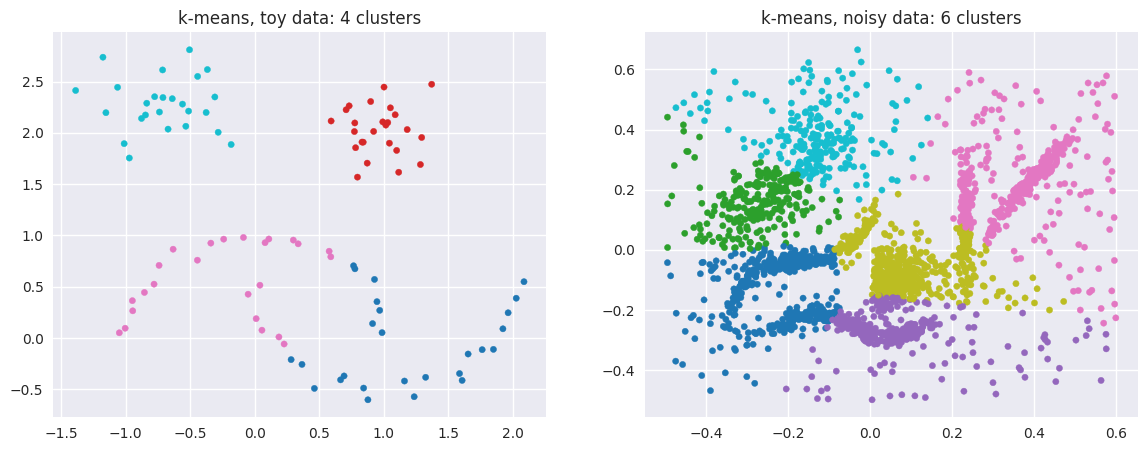

Noisy data, seed 0: inertia = 44.74
Noisy data, seed 1: inertia = 47.65
Noisy data, seed 2: inertia = 43.13


In [5]:
kmeans_toy = KMeans(n_clusters=4)
kmeans_toy.fit(X_toy)
kmeans_noisy = KMeans(n_clusters=6)
kmeans_noisy.fit(X_noisy)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(X_toy, kmeans_toy.labels_, title="k-means, toy data", ax=axes[0])
plot_clusters(X_noisy, kmeans_noisy.labels_, title="k-means, noisy data", ax=axes[1])
plt.show()

# the result depends on the random starting centres
for seed in [0, 1, 2]:
    model = KMeans(n_clusters=6, seed=seed)
    model.fit(X_noisy)
    print(f"Noisy data, seed {seed}: inertia = {model.inertia_:.2f}")

K-means cuts the moons in the wrong places: it looks for round clusters around centres. On the noisy data, every point, including the noise, is forced into a cluster, and different starting centres give different results, with different inertias.

### 1.2 Agglomerative clustering

Agglomerative clustering starts with every point in its own cluster, and merges the two closest clusters, one merge at a time. After each merge, the distances between the new cluster and the others are updated. This update defines the **linkage**:
- **single** linkage: distance between the closest points of the two clusters, $d(i \cup j,\, k) = \min\big(d(i, k),\, d(j, k)\big)$;
- **complete** linkage: distance between the farthest points, $d(i \cup j,\, k) = \max\big(d(i, k),\, d(j, k)\big)$.

Stopping when $K$ clusters remain is the same as cutting the dendrogram at the height where $K$ branches remain.

**Exercise 2.** Complete `agglomerative`.

In [6]:
def agglomerative(X, n_clusters, linkage="single"):
    """Agglomerative clustering of X, stopped when n_clusters clusters remain.

    Parameters:
    -----------
    X: (num_samples, num_features) np.array
    n_clusters: int
    linkage: "single" or "complete"

    Returns:
    --------
    labels: (num_samples,) np.array of cluster labels 0, 1, ..., n_clusters - 1
    """
    # Step 1: distances between all points; a cluster is never merged with itself
    D = cdist(X, X)
    np.fill_diagonal(D, np.inf)

    # Step 2: every point is its own cluster
    labels = np.arange(len(X))

    # Step 3: one merge at a time, until n_clusters clusters remain
    for _ in range(len(X) - n_clusters):
        # a) the two closest clusters
        i, j = np.unravel_index(np.argmin(D), D.shape)

        # b) distances of the merged cluster to the other clusters
        if linkage == "single":
            new_distances = np.minimum(D[i], D[j])
        elif linkage == "complete":
            new_distances = np.maximum(D[i], D[j])
        else:
            raise ValueError('linkage must be "single" or "complete"')

        # c) the merged cluster keeps the name i
        D[i, :] = new_distances
        D[:, i] = new_distances
        D[i, i] = np.inf

        # d) cluster j no longer exists
        D[j, :] = np.inf
        D[:, j] = np.inf

        # e) its points now belong to cluster i
        labels[labels == j] = i

    # Step 4: labels 0, 1, ..., n_clusters - 1
    return np.unique(labels, return_inverse=True)[1]

Compare single and complete linkage on the toy data, with $K = 4$. As a check, the adjusted Rand index between our clusters and those of scikit-learn's `AgglomerativeClustering` should be 1 (the same clusters, whatever their names):

single   linkage, same clusters as scikit-learn: 1.00
complete linkage, same clusters as scikit-learn: 1.00


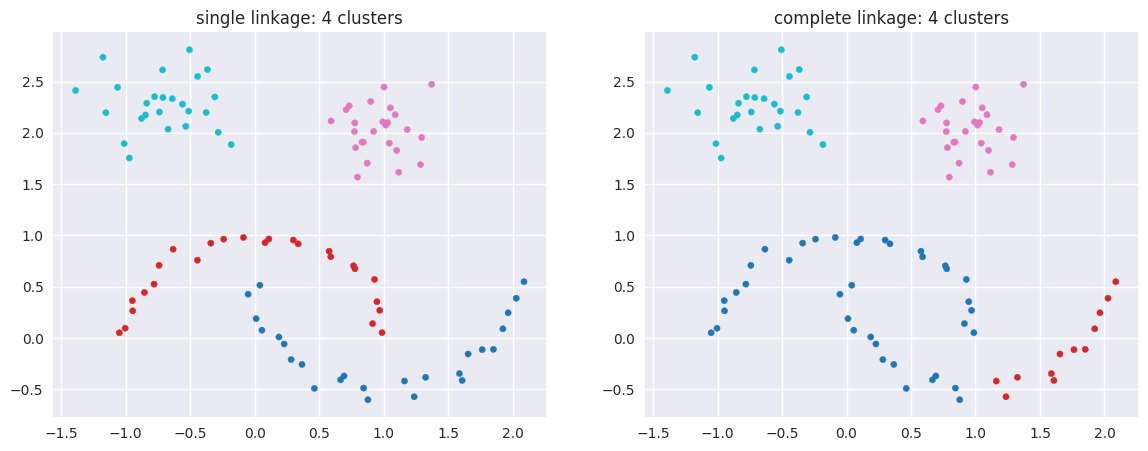

In [7]:
single = agglomerative(X_toy, 4, linkage="single")
complete = agglomerative(X_toy, 4, linkage="complete")

for name, ours in [("single", single), ("complete", complete)]:
    sklearn_labels = AgglomerativeClustering(n_clusters=4, linkage=name).fit_predict(X_toy)
    print(f"{name:8s} linkage, same clusters as scikit-learn: {adjusted_rand_score(sklearn_labels, ours):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(X_toy, single, title="single linkage", ax=axes[0])
plot_clusters(X_toy, complete, title="complete linkage", ax=axes[1])
plt.show()

Single linkage separates the two moons: it follows chains of close points. Complete linkage prefers compact, round clusters, like k-means, and cuts the moons.
The lecture's "Four linkages" slide shows the other side: with noise between two clusters, one bridge of points is enough for single linkage to join them, while complete linkage resists it.

The full history of the merges is the **dendrogram**. Cutting it where 4 branches remain gives the 4 single-linkage clusters:

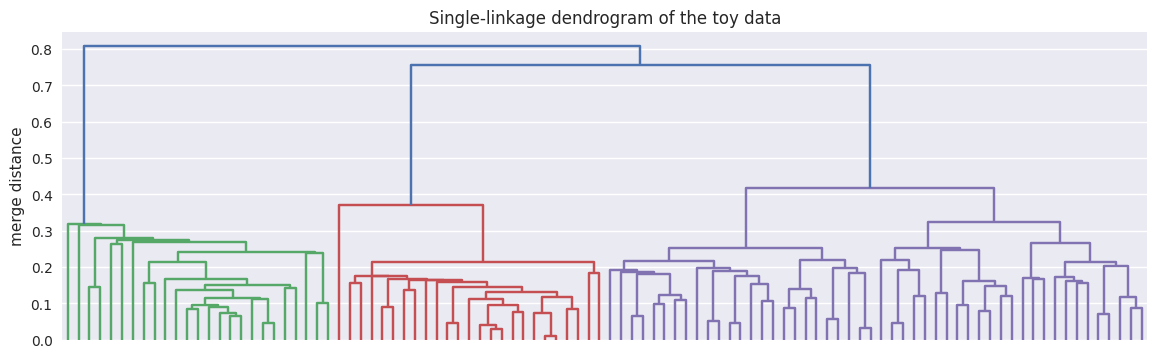

In [8]:
plt.figure(figsize=(14, 4))
hierarchy.dendrogram(hierarchy.linkage(X_toy, method="single"), no_labels=True)
plt.title("Single-linkage dendrogram of the toy data")
plt.ylabel("merge distance")
plt.show()

### 1.3 DBSCAN

DBSCAN finds clusters as dense regions. With two parameters, a radius $\varepsilon$ and a number of points MinPts:
- a **core** point has at least MinPts points within distance $\varepsilon$;
- a **border** point is within $\varepsilon$ of a core point, without being a core point itself;
- the other points are **noise**: they are not put in any cluster.

Clusters are groups of connected core points, with their border points.

To choose $\varepsilon$, we use the **k-NN distance curve**: for every point, the distance to its $k$-th nearest neighbour (with $k$ = MinPts), sorted from smallest to largest. Points in dense regions have small values, noise points have large values, and a good $\varepsilon$ is where the curve starts to rise sharply.

**Exercise 3.** Complete `knn_distances`.

In [9]:
def knn_distances(X, k):
    """Distance from every point to its k-th nearest neighbour, sorted from smallest to largest.

    Parameters:
    -----------
    X: (num_samples, num_features) np.array
    k: int

    Returns:
    --------
    distances: (num_samples,) np.array
    """
    # Step 1: distances between all points
    D = cdist(X, X)

    # Step 2: sort each row; column 0 is the point itself
    D_sorted = np.sort(D, axis=1)

    # Step 3: distance to the k-th nearest neighbour, sorted
    return np.sort(D_sorted[:, k])

The curve for the noisy data, with MinPts = 5:

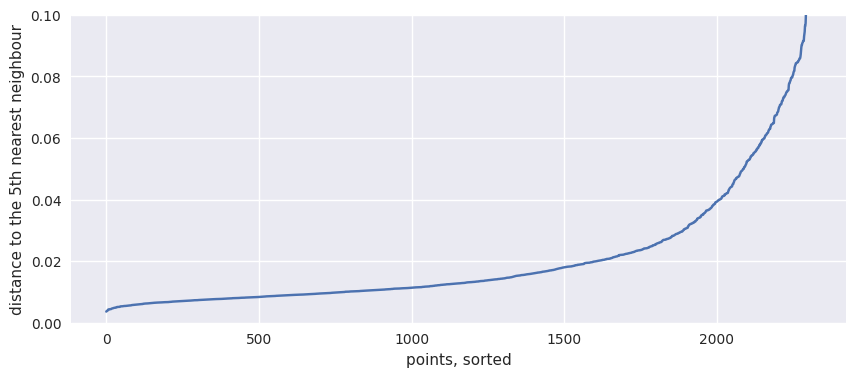

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(knn_distances(X_noisy, k=5))
plt.ylim(0, 0.1)
plt.xlabel("points, sorted")
plt.ylabel("distance to the 5th nearest neighbour")
plt.show()

The curve starts to rise sharply around 0.03. The effect of $\varepsilon$ on DBSCAN (scikit-learn), with MinPts = 5:

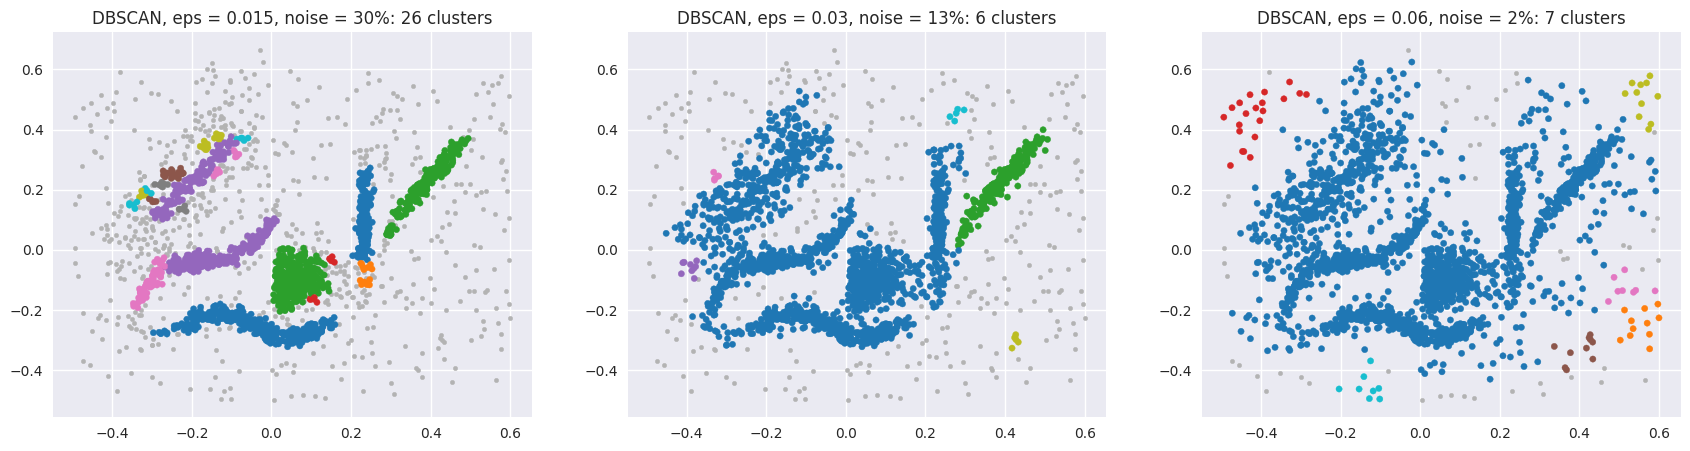

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, eps in zip(axes, [0.015, 0.03, 0.06]):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_noisy)
    plot_clusters(X_noisy, labels, title=f"DBSCAN, eps = {eps}, noise = {np.mean(labels == -1):.0%}", ax=ax)
plt.show()

No value of $\varepsilon$ works well here. With $\varepsilon = 0.015$ the dense parts are found, but 30% of the points are noise and the sparser clusters break into many small pieces. With $\varepsilon = 0.03$ and $0.06$ the clusters touch each other through the noise and merge into one big cluster. The clusters have different densities, so a single radius cannot fit all of them: the k-NN curve gives a starting value, not a guarantee.

### 1.4 HDBSCAN

HDBSCAN runs DBSCAN at every scale at once, builds the hierarchy of the clusters, and keeps the most **stable** ones. There is no $\varepsilon$ to choose, only the smallest cluster size we accept. Compare it with DBSCAN at $\varepsilon = 0.03$:

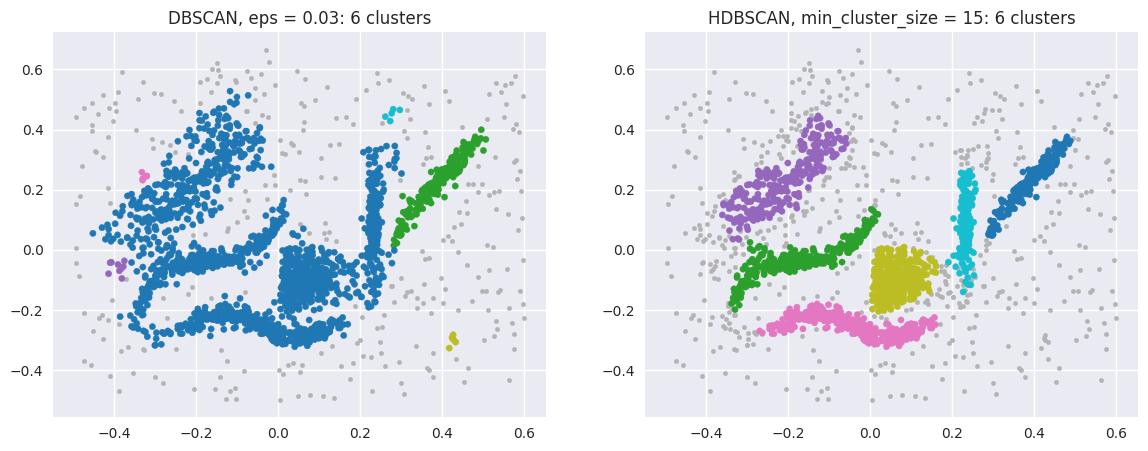

In [12]:
dbscan_labels = DBSCAN(eps=0.03, min_samples=5).fit_predict(X_noisy)
hdbscan_labels = HDBSCAN(min_cluster_size=15).fit_predict(X_noisy)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(X_noisy, dbscan_labels, title="DBSCAN, eps = 0.03", ax=axes[0])
plot_clusters(X_noisy, hdbscan_labels, title="HDBSCAN, min_cluster_size = 15", ax=axes[1])
plt.show()

HDBSCAN finds the six clusters, each at its own density, and leaves the background as noise. DBSCAN, with one $\varepsilon$ for the whole dataset, either breaks them into pieces or merges them.

## Homework: DBSCAN and HDBSCAN from scratch

In class we used scikit-learn for DBSCAN and HDBSCAN. At home, implement them from scratch and check that you find the same clusters.

### DBSCAN

With a radius $\varepsilon$ and a number of points MinPts:
1. the **neighbours** of a point are the points within distance $\varepsilon$ (the point itself counts, as in scikit-learn);
2. a **core** point has at least MinPts neighbours;
3. a cluster starts from a core point that has no cluster yet, and **spreads**: all its neighbours join the cluster, and every neighbour that is a core point spreads the cluster further to its own neighbours;
4. the points reached by no cluster are **noise** (label $-1$).

**Exercise 4 (homework).** Complete `dbscan`.

In [13]:
def dbscan(X, eps, min_samples):
    """DBSCAN clustering of X.

    Parameters:
    -----------
    X: (num_samples, num_features) np.array
    eps: float
        Radius of the neighbourhood
    min_samples: int
        Number of neighbours (the point included) needed to be a core point

    Returns:
    --------
    labels: (num_samples,) np.array, cluster labels 0, 1, ... and -1 for noise
    """
    # Step 1: neighbours within eps (every point is its own neighbour)
    neighbours = cdist(X, X) <= eps

    # Step 2: core points
    core = neighbours.sum(axis=1) >= min_samples

    # Step 3: no point has a cluster yet
    labels = np.full(len(X), -1)
    cluster = 0

    # Step 4: grow one cluster from every core point that has no cluster yet
    for i in range(len(X)):
        if not core[i] or labels[i] != -1:
            continue

        # a) start a new cluster at point i
        labels[i] = cluster
        to_visit = [i]

        # b) spread through the neighbours; only core points spread further
        while to_visit:
            p = to_visit.pop()
            for q in np.where(neighbours[p])[0]:
                if labels[q] == -1:
                    labels[q] = cluster
                    if core[q]:
                        to_visit.append(q)

        # c) next cluster
        cluster = cluster + 1

    # Step 5: cluster of every point, -1 for noise
    return labels

Check: with $\varepsilon = 0.03$ and MinPts = 5, our DBSCAN should find exactly the same clusters as scikit-learn's (adjusted Rand index 1):

Same clusters as scikit-learn: 1.00


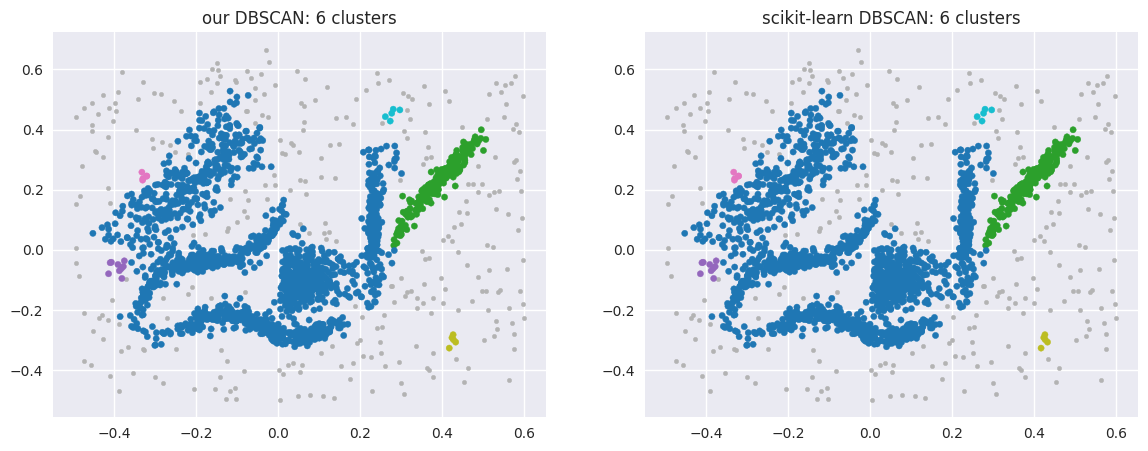

In [14]:
ours = dbscan(X_noisy, eps=0.03, min_samples=5)
sklearn_labels = DBSCAN(eps=0.03, min_samples=5).fit_predict(X_noisy)
print(f"Same clusters as scikit-learn: {adjusted_rand_score(sklearn_labels, ours):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(X_noisy, ours, title="our DBSCAN", ax=axes[0])
plot_clusters(X_noisy, sklearn_labels, title="scikit-learn DBSCAN", ax=axes[1])
plt.show()

### HDBSCAN

HDBSCAN follows the six steps of the lecture. With $k$ = `min_samples`:
1. **core distance** of a point: the distance to its $k$-th nearest neighbour, the point itself counting as the first. It is small in dense regions, and large for isolated points;
2. **mutual reachability distance** between two points: $d_{mr}(a, b) = \max\big(\text{core}(a),\ \text{core}(b),\ d(a, b)\big)$. Isolated points are pushed away from everything, while points in dense regions keep their usual distances;
3. **minimum spanning tree** of the mutual reachability distances: the shortest set of edges that connects all the points;
4. **cluster hierarchy**: remove the edges of the tree from the longest to the shortest, which splits the data into smaller and smaller clusters (single linkage, read from the top);
5. **condensed tree**: a split counts only when both sides have at least `min_cluster_size` points; otherwise the small side "falls out" of the cluster;
6. **stability**: keep the clusters that live the longest in the condensed tree.

**Exercise 5 (homework).** Complete `core_distances`, `mutual_reachability` and `minimum_spanning_tree` (steps 1 to 3). Steps 4 to 6 are given in `clusters_from_tree`: read them with the lecture's slides.

In [15]:
def core_distances(X, k):
    """Distance from every point to its k-th nearest neighbour, the point itself counting as the first."""
    # Step 1: distances between all points
    D = cdist(X, X)

    # Step 2: sort each row; column 0 is the point itself
    D_sorted = np.sort(D, axis=1)

    # Step 3: distance to the k-th nearest neighbour
    return D_sorted[:, k - 1]


def mutual_reachability(X, k):
    """Mutual reachability distance max(core(a), core(b), d(a, b)) between all pairs of points."""
    # Step 1: distances and core distances
    D = cdist(X, X)
    core = core_distances(X, k)

    # Step 2: largest core distance of each pair
    core_pairs = np.maximum(core[:, None], core[None, :])

    # Step 3: the mutual reachability distance
    return np.maximum(D, core_pairs)


def minimum_spanning_tree(M):
    """Minimum spanning tree of the distance matrix M, built with Prim's algorithm.

    Returns:
    --------
    edges: list of (point_a, point_b, distance), num_samples - 1 edges
    """
    # Step 1: the tree starts with point 0
    in_tree = np.zeros(len(M), dtype=bool)
    in_tree[0] = True

    # Step 2: cheapest link of every point to the tree, and the tree point it comes from
    best = M[0].copy()
    closest = np.zeros(len(M), dtype=int)

    # Step 3: add one point at a time
    edges = []
    for _ in range(len(M) - 1):
        # a) the point outside the tree with the cheapest link
        j = np.argmin(np.where(in_tree, np.inf, best))

        # b) add its edge to the tree
        edges.append((closest[j], j, best[j]))
        in_tree[j] = True

        # c) some points are now closer to j than to the rest of the tree
        closer = M[j] < best
        best = np.where(closer, M[j], best)
        closest = np.where(closer, j, closest)

    # Step 4: the edges of the tree
    return edges

Steps 4 to 6 (given). Read the comments with the slides "Step 4: cluster hierarchy", "Step 5: condense the tree" and "Step 6: keep the stable clusters":

In [16]:
def clusters_from_tree(edges, n, min_cluster_size):
    """Steps 4 to 6 of HDBSCAN: cluster hierarchy, condensed tree and stability.
    Returns the cluster label of each of the n points, -1 for noise."""
    # ---- Step 4: cluster hierarchy
    # Merge the points along the edges of the tree, from the shortest edge to the longest (single linkage).
    # Nodes 0, ..., n - 1 are the points; every merge creates a new node n, n + 1, ..., 2n - 2 (the root).
    edges = sorted(edges, key=lambda edge: edge[2])
    top = np.arange(2 * n - 1)              # current top node of every node
    children = {}                           # merge node -> its two child nodes
    size = np.ones(2 * n - 1, dtype=int)    # number of points under each node
    height = np.zeros(2 * n - 1)            # distance at which each merge happens

    def find_top(a):
        while top[a] != a:
            top[a] = top[top[a]]            # shortcut, to keep the search short
            a = top[a]
        return a

    for new_node, (a, b, distance) in enumerate(edges, start=n):
        top_a, top_b = find_top(a), find_top(b)
        children[new_node] = (top_a, top_b)
        size[new_node] = size[top_a] + size[top_b]
        height[new_node] = distance
        top[top_a] = top[top_b] = new_node
    root = 2 * n - 2

    def points_under(node):
        stack, points = [node], []
        while stack:
            v = stack.pop()
            if v < n:
                points.append(v)
            else:
                stack.extend(children[v])
        return points

    # ---- Step 5: condensed tree
    # Go down from the root. lambda = 1 / distance grows as the clusters get denser.
    # A split where both sides have at least min_cluster_size points creates two new clusters;
    # otherwise the small side falls out of the current cluster, and its points leave it at this lambda.
    birth = [0.0]           # lambda at which each cluster appears (cluster 0 = all the points)
    parent = [-1]           # parent cluster of each cluster
    stability = [0.0]       # step 6: sum over the points of (lambda when they leave - lambda at birth)
    last_cluster = np.zeros(n, dtype=int)   # last cluster each point belonged to

    to_visit = [(root, 0)]
    while to_visit:
        node, cluster = to_visit.pop()
        lam = 1 / height[node]
        left, right = children[node]
        if size[left] >= min_cluster_size and size[right] >= min_cluster_size:
            # a real split: all the points of the node leave the cluster, into two new clusters
            stability[cluster] += size[node] * (lam - birth[cluster])
            for child in (left, right):
                birth.append(lam)
                parent.append(cluster)
                stability.append(0.0)
                to_visit.append((child, len(birth) - 1))
        else:
            for child in (left, right):
                if size[child] >= min_cluster_size:
                    to_visit.append((child, cluster))    # the cluster continues in this child
                else:
                    points = points_under(child)         # these points fall out of the cluster
                    stability[cluster] += len(points) * (lam - birth[cluster])
                    last_cluster[points] = cluster

    # ---- Step 6: keep the stable clusters
    # From the bottom up: keep a cluster if it is more stable than all its sub-clusters together,
    # otherwise keep its sub-clusters. The root (all the points) is never kept.
    n_clusters = len(birth)
    kids = [[] for _ in range(n_clusters)]
    for c in range(1, n_clusters):
        kids[parent[c]].append(c)
    best = list(stability)                  # best total stability that can be kept below each cluster
    selected = np.zeros(n_clusters, dtype=bool)
    for c in range(n_clusters - 1, 0, -1):  # sub-clusters have larger numbers than their parent
        kids_stability = sum(best[k] for k in kids[c])
        if kids[c] and kids_stability > stability[c]:
            best[c] = kids_stability
        else:
            selected[c] = True
            stack = list(kids[c])           # its sub-clusters are no longer kept
            while stack:
                k = stack.pop()
                selected[k] = False
                stack.extend(kids[k])

    # every point takes the kept cluster above its last cluster, or -1 (noise) if there is none
    new_label = np.full(n_clusters, -1)
    new_label[selected] = np.arange(selected.sum())
    labels = np.full(n, -1)
    for point in range(n):
        c = last_cluster[point]
        while c != -1 and not selected[c]:
            c = parent[c]
        if c != -1:
            labels[point] = new_label[c]
    return labels


def hdbscan(X, min_cluster_size, min_samples=None):
    """HDBSCAN clustering of X: steps 1 to 3 (yours), then steps 4 to 6 (given)."""
    k = min_samples if min_samples is not None else min_cluster_size   # same default as scikit-learn
    M = mutual_reachability(X, k)
    edges = minimum_spanning_tree(M)
    return clusters_from_tree(edges, len(X), min_cluster_size)

Check: with `min_cluster_size = 15`, our HDBSCAN should find the same clusters as scikit-learn's (an adjusted Rand index very close to 1; tiny differences can come from ties between equal distances):

Same clusters as scikit-learn: 0.999


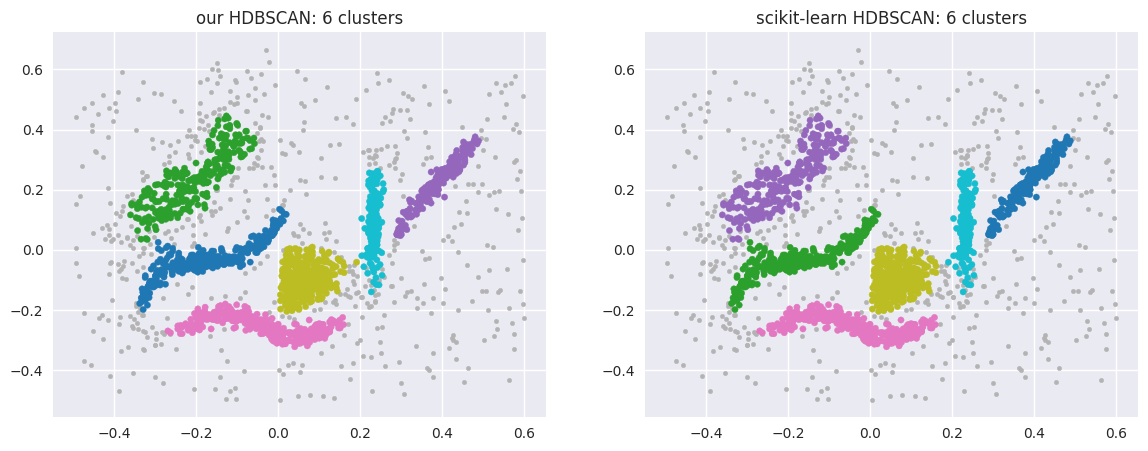

In [17]:
ours = hdbscan(X_noisy, min_cluster_size=15)
sklearn_labels = HDBSCAN(min_cluster_size=15).fit_predict(X_noisy)
print(f"Same clusters as scikit-learn: {adjusted_rand_score(sklearn_labels, ours):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(X_noisy, ours, title="our HDBSCAN", ax=axes[0])
plot_clusters(X_noisy, sklearn_labels, title="scikit-learn HDBSCAN", ax=axes[1])
plt.show()